Mounted at /content/drive
Epoch 1/10
Loss: 0.3893
Val Accuracy: 0.8983
----------------------------------------
Epoch 2/10
Loss: 0.0828
Val Accuracy: 0.9153
----------------------------------------
Epoch 3/10
Loss: 0.0638
Val Accuracy: 0.8136
----------------------------------------
Epoch 4/10
Loss: 0.1529
Val Accuracy: 0.8644
----------------------------------------
Epoch 5/10
Loss: 0.0695
Val Accuracy: 0.9322
----------------------------------------
Epoch 6/10
Loss: 0.0294
Val Accuracy: 0.7966
----------------------------------------
Epoch 7/10
Loss: 0.0516
Val Accuracy: 0.9322
----------------------------------------
Epoch 8/10
Loss: 0.0286
Val Accuracy: 0.9322
----------------------------------------
Epoch 9/10
Loss: 0.0170
Val Accuracy: 0.9492
----------------------------------------
Epoch 10/10
Loss: 0.0153
Val Accuracy: 0.9492
----------------------------------------
Test Accuracy: 0.9836065573770492
              precision    recall  f1-score   support

       jeans       1.00 

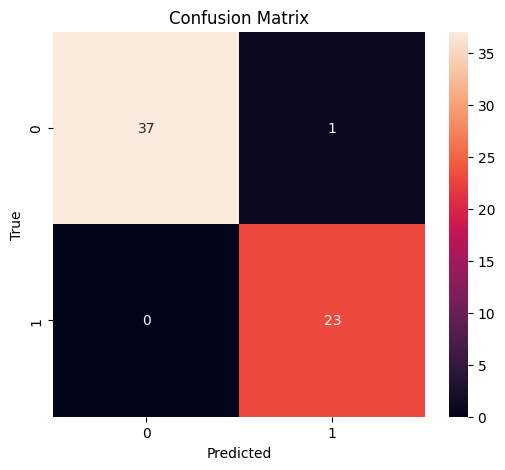

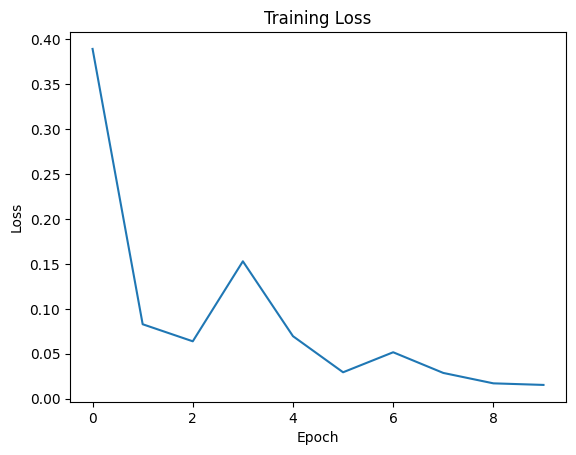

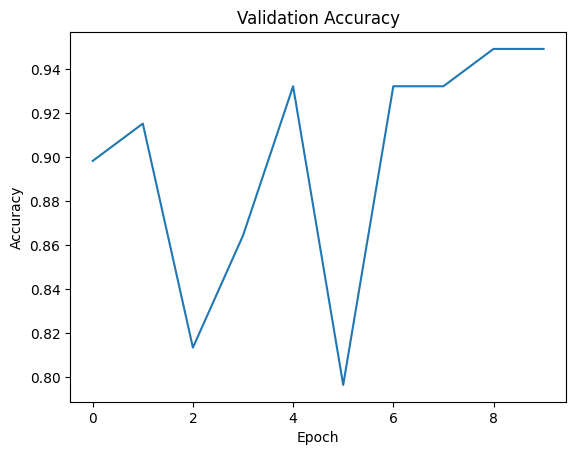

In [4]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
from torchvision.datasets import ImageFolder
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
drive.mount('/content/drive')

dataset_path = os.listdir("/content/drive/MyDrive/cloth_dataset")
# Трансформации для обучающей выборки
train_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5),
                         (0.5, 0.5, 0.5))
])
# Трансформации для тестовой и валидационной выборки
test_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5),
                         (0.5, 0.5, 0.5))
])
# Загрузка полного датасета
full_dataset = datasets.ImageFolder(root="/content/drive/MyDrive/cloth_dataset", transform=train_transform)

# Разделение на обучающую, валидационную и тестовую выборки
train_size = int(0.7 * len(full_dataset))
val_size = int(0.15 * len(full_dataset))
test_size = len(full_dataset) - train_size - val_size
train_data, val_data, test_data = random_split(
    full_dataset,
    [train_size, val_size, test_size]
)
# Применение трансформаций
train_data.dataset.transform = train_transform
val_data.dataset.transform = test_transform
test_data.dataset.transform = test_transform
# Создание DataLoader'ов
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
val_loader = DataLoader(val_data, batch_size=32, shuffle=False)
test_loader = DataLoader(test_data, batch_size=32, shuffle=False)
# Определение архитектуры сверточной нейронной сети
class CNNClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.pool = nn.MaxPool2d(2, 2)
        self.dropout = nn.Dropout(0.5)
        self.adaptive_pool = nn.AdaptiveAvgPool2d((4, 4))
        self.fc1 = nn.Linear(128 * 4 * 4, 256)
        self.fc2 = nn.Linear(256, 2)
    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))
        x = self.adaptive_pool(x)
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        return self.fc2(x)
# Инициализация устройства
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CNNClassifier().to(device)
# Определение функции потерь и оптимизатора
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
# Параметры обучения
epochs = 10
train_losses = []
val_accuracies = []
# Цикл обучения
for epoch in range(epochs):
    model.train()
    running_loss = 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    train_loss = running_loss / len(train_loader)
    train_losses.append(train_loss)
    # Валидация
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_acc = correct / total
    val_accuracies.append(val_acc)
    print(f"Epoch {epoch+1}/{epochs}")
    print(f"Loss: {train_loss:.4f}")
    print(f"Val Accuracy: {val_acc:.4f}")
    print("-" * 40)
# Тестирование модели
model.eval()
y_true = []
y_pred = []
correct = 0
total = 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predicted.cpu().numpy())
# Метрики качества
accuracy = correct / total
print("Test Accuracy:", accuracy)
print(classification_report(
    y_true,
    y_pred,
    target_names=full_dataset.classes
))
# Матрица ошибок
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

# График потерь
plt.figure()
plt.plot(train_losses)
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()
# График точности на валидации
plt.figure()
plt.plot(val_accuracies)
plt.title("Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.show()